In [1]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
import os
import pandas as pd

# Downloads to a cache folder (only the first time) and gives you its path
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print(os.listdir(path))

['amz_uk_price_prediction_dataset.csv']


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
import sys
print(sys.executable)

C:\Users\catar\anaconda3\python.exe


In [5]:
df = pd.read_csv(os.path.join(path, "amz_uk_price_prediction_dataset.csv"))
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
Objective: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [6]:
# Frequency table
frequency_table = df['category'].value_counts()
frequency_table.head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

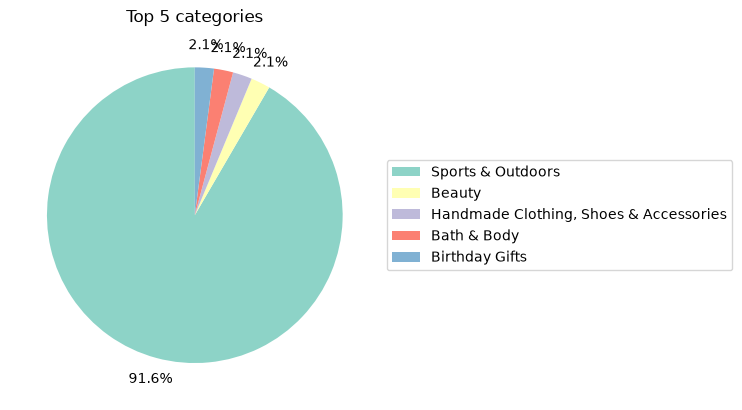

In [7]:
top5 = frequency_table.head(5)

top5.plot.pie(autopct='%.1f%%', startangle=90, labels=None,
              colors=sns.color_palette("Set3"), pctdistance=1.15)
plt.legend(top5.index, loc="center left", bbox_to_anchor=(1, 0.5))
plt.ylabel("")
plt.title("Top 5 categories")
plt.show()

In [8]:
# 1. Measures of Centrality:
# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()

print(mean_price)
print(median_price)
print(mode_price)

89.24380943923661
19.09
0    9.99
Name: price, dtype: float64


In [15]:
# 2.Measures of Dispersion:

# Determine the variance, standard deviation, range, and interquartile range for product price.
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])
iqr_price = quantiles_price[0.75] - quantiles_price[0.25]

print(f"Variance: {variance_price:.2f}")
print(f"Standart deviation: {std_dev_price:.2f}")
print(f"Range: {range_price:.2f}")
print(f"IQR: {iqr_price:.2f}")

Variance: 119445.49
Standart deviation: 345.61
Range: 100000.00
IQR: 36.00


In [12]:
# How varied are the product prices? Are there any indicators of a significant spread in prices?
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


Conclusion: 

The mean price is £89.24, but the median is only £19.09 and the most common price (mode) is £9.99.
The mean is much higher than the median and the mode, which means the price distribution is right skewed; most products are cheap, but a small number of very expensive products pull the average up.
So the mean doesn’t describe a typical product well. The median is a better measure of the typical price, and £9.99 is the single most frequent price point.

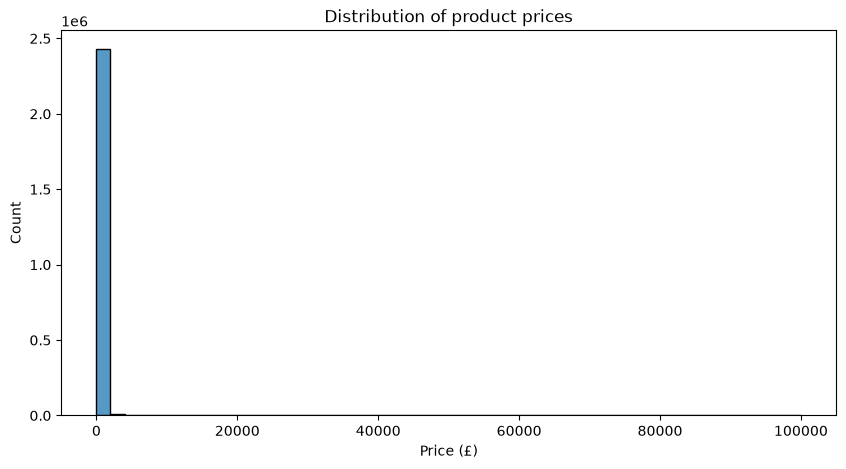

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=50)
plt.title("Distribution of product prices")
plt.xlabel("Price (£)")
plt.show()

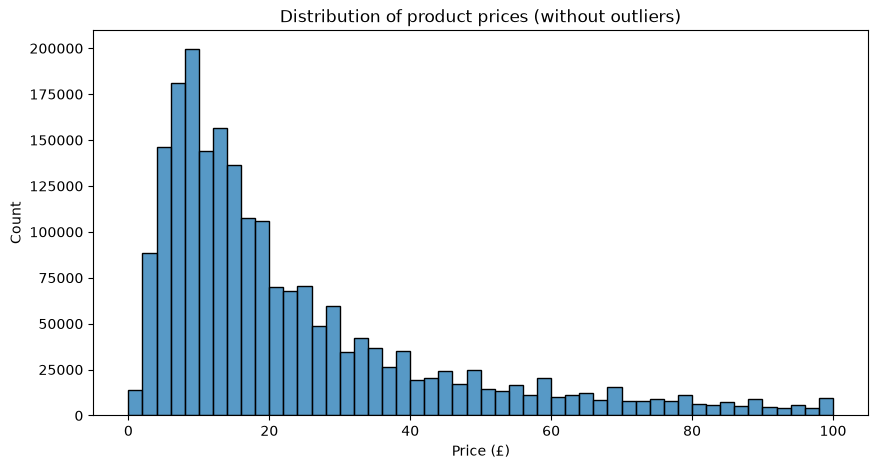

In [17]:
upper_limit = quantiles_price[0.75] + 1.5 * iqr_price
prices_no_outliers = df[df["price"] <= upper_limit]["price"]

plt.figure(figsize=(10, 5))
sns.histplot(prices_no_outliers, bins=50)
plt.title("Distribution of product prices (without outliers)")
plt.xlabel("Price (£)")
plt.show()

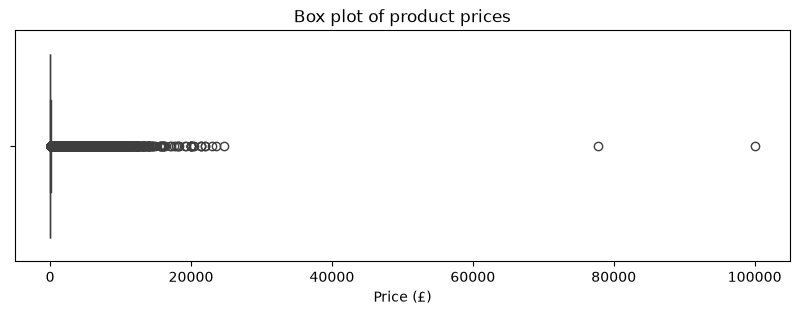

In [18]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["price"])
plt.title("Box plot of product prices")
plt.xlabel("Price (£)")
plt.show()

Conclusion:

The first histogram is unreadable because a few very expensive products (up to £100,000) stretch the x-axis. Removing prices above the upper fence (£99.99) shows the real shape.
Most products fall in a low price range, with the middle 50% between £9.99 and £45.99.
The box plot shows many outliers above the upper fence, so yes, some products are priced much higher than the rest. They’re a small share of listings, but they pull the mean (£89.24) far above the median (£19.09).

In [19]:
mean_stars = df["stars"].mean()
median_stars = df["stars"].median()
mode_stars = df["stars"].mode()[0]

print(f"Mean: {mean_stars:.2f}")
print(f"Median: {median_stars:.2f}")
print(f"Mode: {mode_stars:.2f}")

Mean: 2.15
Median: 0.00
Mode: 0.00


In [20]:
rated = df[df["stars"] > 0]["stars"]

print(f"Products with ratings: {len(rated)} of {len(df)}")
print(f"Mean (rated only): {rated.mean():.2f}")
print(f"Median (rated only): {rated.median():.2f}")
print(f"Mode (rated only): {rated.mode()[0]:.2f}")

Products with ratings: 1218010 of 2443651
Mean (rated only): 4.32
Median (rated only): 4.40
Mode (rated only): 4.50


In [21]:
variance_stars = df["stars"].var()
std_stars = df["stars"].std()
quantiles_stars = df["stars"].quantile([0.25, 0.75])
iqr_stars = quantiles_stars[0.75] - quantiles_stars[0.25]

print(f"Variance: {variance_stars:.2f}")
print(f"Standard deviation: {std_stars:.2f}")
print(f"IQR: {iqr_stars:.2f}")

Variance: 4.82
Standard deviation: 2.19
IQR: 4.40


In [22]:
print(f"Skewness: {df['stars'].skew():.2f}")
print(f"Kurtosis: {df['stars'].kurtosis():.2f}")

print(f"Skewness (rated only): {rated.skew():.2f}")
print(f"Kurtosis (rated only): {rated.kurtosis():.2f}")

Skewness: 0.08
Kurtosis: -1.93
Skewness (rated only): -2.38
Kurtosis (rated only): 9.78


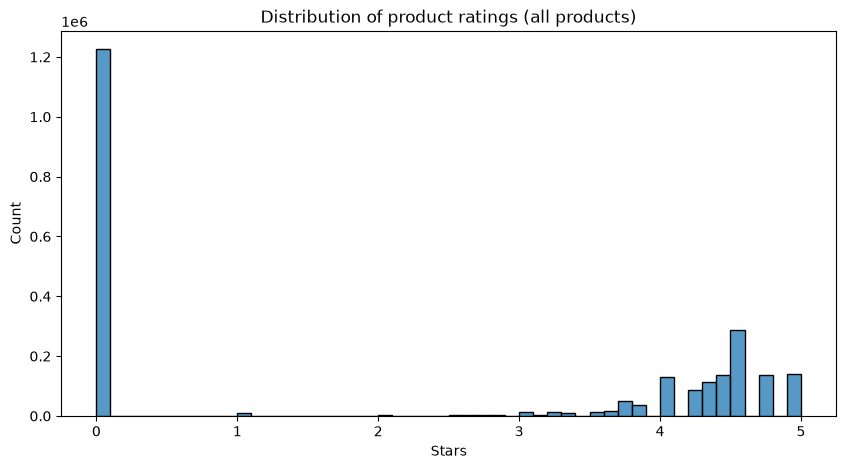

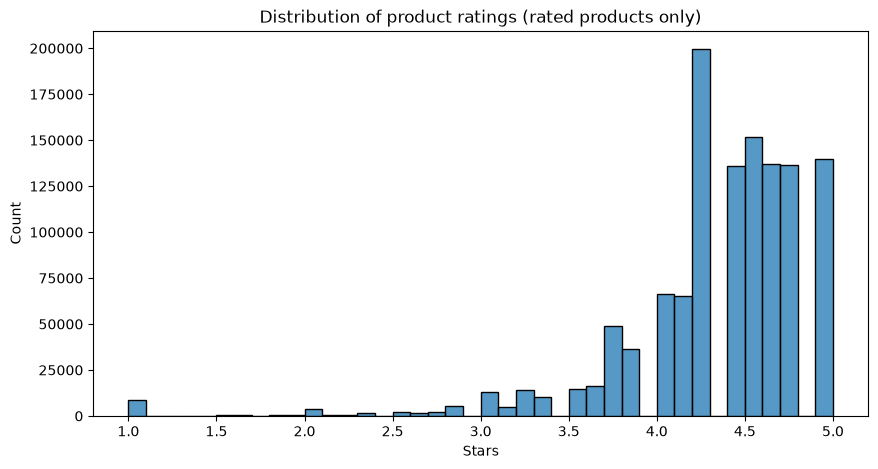

In [23]:
plt.figure(figsize=(10, 5))
sns.histplot(df["stars"], bins=50)
plt.title("Distribution of product ratings (all products)")
plt.xlabel("Stars")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(rated, bins=40)
plt.title("Distribution of product ratings (rated products only)")
plt.xlabel("Stars")
plt.show()

Conclusion: 

More than half of the products (50.2%) have no ratings yet (0 stars). That’s why the overall mean is low (2.15) and the median is 0.
Among products with ratings, customers are mostly happy: the average is 4.32, the median 4.40, and the most common rating is 4.50.
Low ratings are rare, so the ratings lean towards high values (negatively skewed) and aren’t normally distributed.